03. Single-Backbone-Edit PAMPA Analysis
Question: When the side-chain scaffold is fixed, how is measured PAMPA associated with a single elementary backbone modification?

A clean elementary edit is one of:
- none → D
- none → NMe
- D → D+NMe
- NMe → D+NMe
This is an observational matched-pair analysis. It does not establish that an edit causally changes permeability.

In [1]:
from pathlib import Path
import sys
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "analysis").exists():
            return candidate
    raise RuntimeError(
        "Could not find the PepGate repository root. "
        "Open this notebook from inside the PepGate repository."
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"
DATA = ROOT / "data"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PepGate root:", ROOT)

PepGate root: /Users/yeritmaryrodriguezdelgado/Desktop/PEPGATE_YRD


In [2]:
PAIR_PATH = OUTPUTS / "single_edit_pairs.csv"
assert PAIR_PATH.exists(), (
    f"Missing {PAIR_PATH}. Run analysis/single_edit_pairs.py first."
)

pairs = pd.read_csv(PAIR_PATH, low_memory=False)
clean = pairs[pairs["clean_single_edit"] == True].copy()

clean["delta_PAMPA"] = pd.to_numeric(clean["delta_PAMPA"], errors="coerce")
clean["transition"] = (
    clean["reference_state"].astype(str)
    + " → "
    + clean["modified_state"].astype(str)
)

print(f"One-position pairs: {len(pairs):,}")
print(f"Clean elementary single edits: {len(clean):,}")
display(clean.head())

One-position pairs: 6,836
Clean elementary single edits: 4,933


,Source,sidechain_signature,position,pattern_a,pattern_b,state_a,state_b,PAMPA_a,PAMPA_b,IDs_a,IDs_b,one_position_difference,clean_single_edit,reference_state,modified_state,edit_type,reference_PAMPA,modified_PAMPA,delta_PAMPA,transition
0,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",4,"('D', 'D', 'D', 'D', 'D', 'none')","('D', 'D', 'D', 'D', 'none', 'none')",D,none,-7.3,-7.0,7,3,True,True,none,D,D,-7.0,-7.3,-0.3,none → D
1,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",2,"('D', 'D', 'D', 'D', 'none', 'none')","('D', 'D', 'none', 'D', 'none', 'none')",D,none,-7.0,-6.2,3,2,True,True,none,D,D,-6.2,-7.0,-0.8,none → D
2,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",0,"('D', 'D', 'D', 'D', 'none', 'none')","('none', 'D', 'D', 'D', 'none', 'none')",D,none,-7.0,-7.2,3,5,True,True,none,D,D,-7.2,-7.0,0.2,none → D
3,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",1,"('none', 'D', 'D', 'D', 'none', 'none')","('none', 'none', 'D', 'D', 'none', 'none')",D,none,-7.2,-7.3,5,8,True,True,none,D,D,-7.3,-7.2,0.1,none → D
4,2006_Rezai_1,"('Leu', 'Leu', 'Leu', 'Leu', 'Pro', 'Tyr')",3,"('none', 'D', 'none', 'D', 'D', 'none')","('none', 'D', 'none', 'none', 'D', 'none')",D,none,-8.1,-8.1,9,10,True,True,none,D,D,-8.1,-8.1,0.0,none → D


1. Which backbone edits are represented?

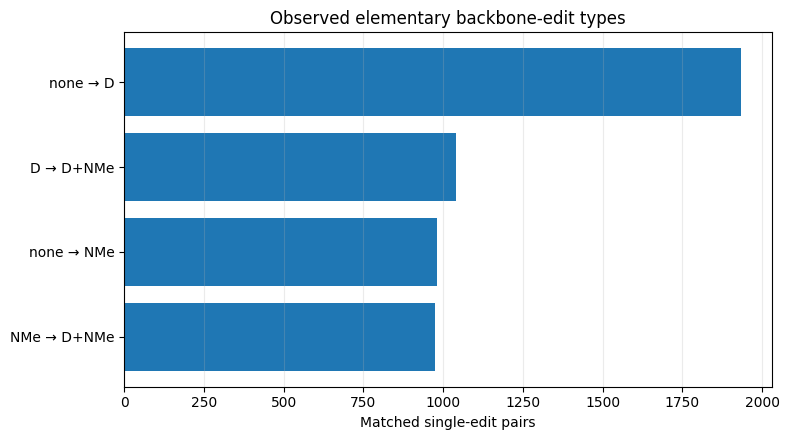

,pairs
transition,
NMe → D+NMe,976
none → NMe,982
D → D+NMe,1041
none → D,1934


In [3]:
transition_counts = clean["transition"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(transition_counts.index, transition_counts.values)
ax.set_xlabel("Matched single-edit pairs")
ax.set_title("Observed elementary backbone-edit types")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(transition_counts.rename("pairs").to_frame())

2. Overall ΔPAMPA distribution

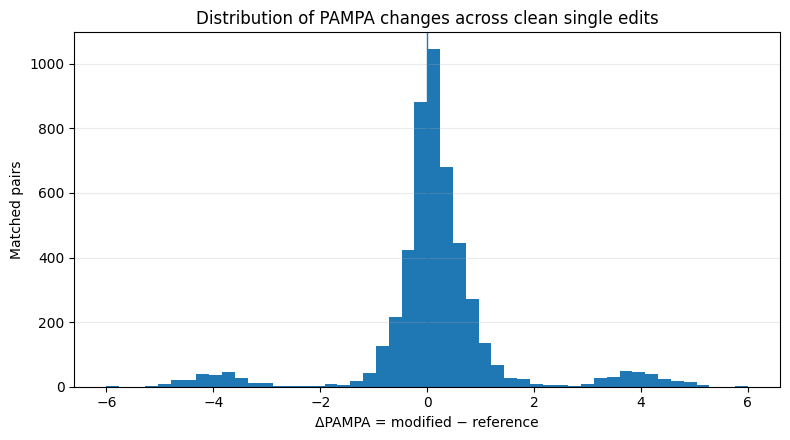

Median ΔPAMPA: 0.0899999999999998


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(clean["delta_PAMPA"].dropna(), bins=50)
ax.axvline(0, linewidth=1)
ax.set_xlabel("ΔPAMPA = modified − reference")
ax.set_ylabel("Matched pairs")
ax.set_title("Distribution of PAMPA changes across clean single edits")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Median ΔPAMPA:", clean["delta_PAMPA"].median())

3. Positive, negative, and unchanged outcomes

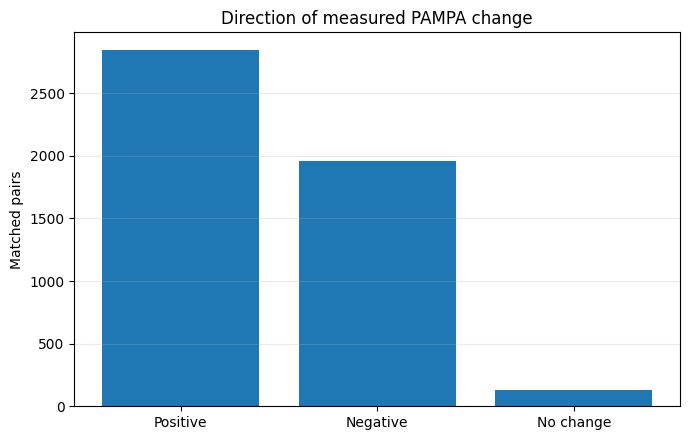

,pairs
direction,
Positive,2843
Negative,1962
No change,128


In [5]:
eps = 1e-12
clean["direction"] = np.select(
    [
        clean["delta_PAMPA"] > eps,
        clean["delta_PAMPA"] < -eps,
    ],
    [
        "Positive",
        "Negative",
    ],
    default="No change",
)

direction_counts = clean["direction"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(direction_counts.index, direction_counts.values)
ax.set_ylabel("Matched pairs")
ax.set_title("Direction of measured PAMPA change")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(direction_counts.rename("pairs").to_frame())

4. ΔPAMPA by edit type

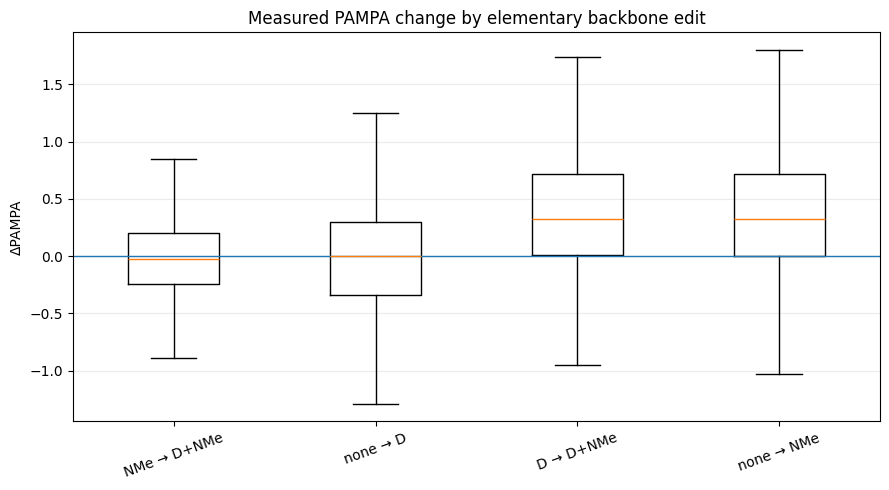

,transition,n_pairs,median_delta_PAMPA,mean_delta_PAMPA
0,D → D+NMe,1041,0.32,0.428713
3,none → NMe,982,0.32,0.410789
2,none → D,1934,0.00,-0.047751
1,NMe → D+NMe,976,-0.03,-0.066025


In [6]:
order = (
    clean.groupby("transition")["delta_PAMPA"]
    .median()
    .sort_values()
    .index
    .tolist()
)

data = [
    clean.loc[clean["transition"] == transition, "delta_PAMPA"].dropna().values
    for transition in order
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, tick_labels=order, showfliers=False)
ax.axhline(0, linewidth=1)
ax.set_ylabel("ΔPAMPA")
ax.set_title("Measured PAMPA change by elementary backbone edit")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

edit_summary = (
    clean.groupby("transition", as_index=False)
    .agg(
        n_pairs=("delta_PAMPA", "size"),
        median_delta_PAMPA=("delta_PAMPA", "median"),
        mean_delta_PAMPA=("delta_PAMPA", "mean"),
    )
    .sort_values("median_delta_PAMPA", ascending=False)
)

display(edit_summary)

5. Before vs after PAMPA

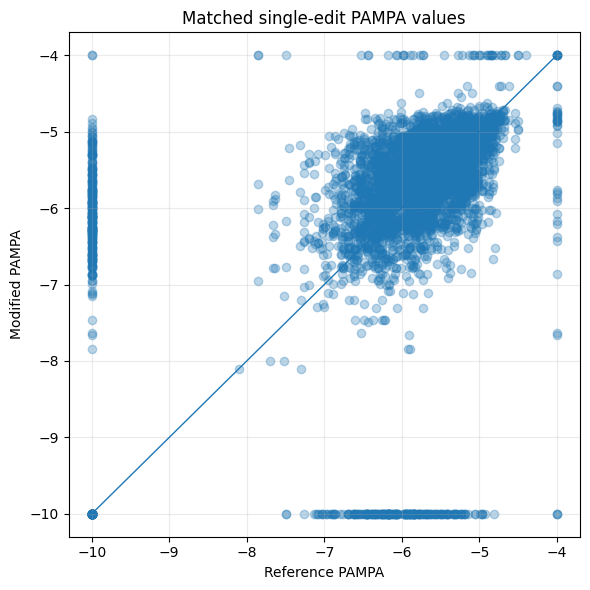

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(clean["reference_PAMPA"], clean["modified_PAMPA"], alpha=0.3)

vals = pd.concat([
    pd.to_numeric(clean["reference_PAMPA"], errors="coerce"),
    pd.to_numeric(clean["modified_PAMPA"], errors="coerce"),
]).dropna()

low, high = vals.min(), vals.max()
ax.plot([low, high], [low, high], linewidth=1)
ax.set_xlabel("Reference PAMPA")
ax.set_ylabel("Modified PAMPA")
ax.set_title("Matched single-edit PAMPA values")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

6. Townsend sensitivity

In [8]:
clean["is_townsend"] = clean["Source"].eq("2020_Townsend")

sensitivity = (
    clean.groupby(["is_townsend", "transition"], as_index=False)
    .agg(
        n_pairs=("delta_PAMPA", "size"),
        median_delta_PAMPA=("delta_PAMPA", "median"),
    )
)

display(sensitivity)

non_townsend = clean[~clean["is_townsend"]].copy()
print("Non-Townsend clean pairs:", len(non_townsend))
print("Non-Townsend parents:", non_townsend["sidechain_signature"].nunique())

,is_townsend,transition,n_pairs,median_delta_PAMPA
0,False,D → D+NMe,9,0.07
1,False,NMe → D+NMe,7,0.78
2,False,none → D,28,-0.04
3,False,none → NMe,33,0.22
4,True,D → D+NMe,1032,0.33
5,True,NMe → D+NMe,969,-0.03
6,True,none → D,1906,0.00
7,True,none → NMe,949,0.33


Non-Townsend clean pairs: 77
Non-Townsend parents: 20


Takeaway
Single backbone edits frequently coincide with measurable changes in PAMPA while the side-chain scaffold is held fixed. Because the matched-pair dataset is heavily source-imbalanced and pairs within the same parent are not statistically independent, these results are best used as motivation for constrained optimization, not as causal estimates of individual chemical edits.